# Telco customer churn — exploratory analysis

This notebook explores three questions:

1. How imbalanced is churn, and why is accuracy alone insufficient?
2. How do churn rates vary with contract, tenure and internet service?
3. What data-quality issues need attention before training?

The dataset is fictional. Relationships shown here are descriptive and do not establish causes.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from churn.data import load_dataset

%matplotlib inline

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 9,
    "axes.edgecolor": "#7b8794",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e7eb",
    "axes.titleweight": "semibold",
})
INK, ACCENT, COOL = "#1f2933", "#b44d3b", "#3d6b7d"

df = load_dataset()
print(f"{df.shape[0]:,} customers x {df.shape[1]} columns")
df.head(3)

7,043 customers x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1.0,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34.0,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2.0,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## 1. The target is imbalanced

Churn sits at roughly one in four customers. That single fact invalidates accuracy as a headline metric: predicting "nobody churns" would already score ~73.5%.


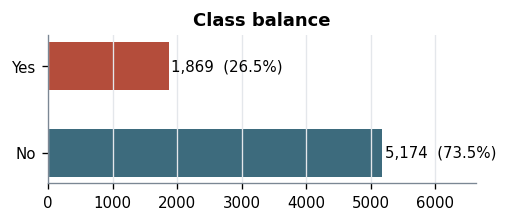

Majority-class accuracy of a do-nothing model: 73.5%
Minority class: 1,869 churners across 7,043 rows


In [2]:
rate = (df["Churn"] == "Yes").mean()
counts = df["Churn"].value_counts()

fig, ax = plt.subplots(figsize=(4.6, 1.6))
ax.barh(counts.index, counts.values, color=[COOL, ACCENT], height=0.55)
for i, value in enumerate(counts.values):
    ax.text(value + 40, i, f"{value:,}  ({value / len(df):.1%})", va="center", fontsize=9)
ax.set_xlim(0, counts.max() * 1.28)
ax.set_title("Class balance")
ax.grid(axis="y", visible=False)
plt.show()

print(f"Majority-class accuracy of a do-nothing model: {1 - rate:.1%}")
print(f"Minority class: {counts['Yes']:,} churners across {len(df):,} rows")

## 2. `TotalCharges` is stored as text

Eleven values are blank, all in rows where `tenure == 0`. The project treats those blanks as zero total charges rather than discarding these records. A direct conversion with `astype(float)` fails on the blanks. Note that all 11 of these customers are labelled as non-churners; the sample is too small to draw conclusions about their churn risk.

In [3]:
raw = pd.read_csv(ROOT / "data" / "raw" / "telco_churn.csv")
blank = raw["TotalCharges"].str.strip() == ""

print(f"TotalCharges dtype in raw file : {raw['TotalCharges'].dtype}")
print(f"Blank values                   : {blank.sum()}")
print(f"Tenure of those customers      : {sorted(raw.loc[blank, 'tenure'].unique())}")
print(f"Churn rate among them          : {(raw.loc[blank, 'Churn'] == 'Yes').mean():.1%} "
      f"(vs {(raw['Churn'] == 'Yes').mean():.1%} overall)")
print(f"After clean()                  : {df['TotalCharges'].dtype}, {df['TotalCharges'].isna().sum()} nulls")

TotalCharges dtype in raw file : object
Blank values                   : 11
Tenure of those customers      : [np.int64(0)]
Churn rate among them          : 0.0% (vs 26.5% overall)
After clean()                  : float64, 0 nulls


## 3. Where does churn concentrate?

Tenure and contract type carry most of the signal. Month-to-month customers churn at several times the rate of two-year customers, and risk falls steadily with tenure — the classic pattern, and the reason the final model ranks `tenure` and `Contract` at the top of its permutation importances.


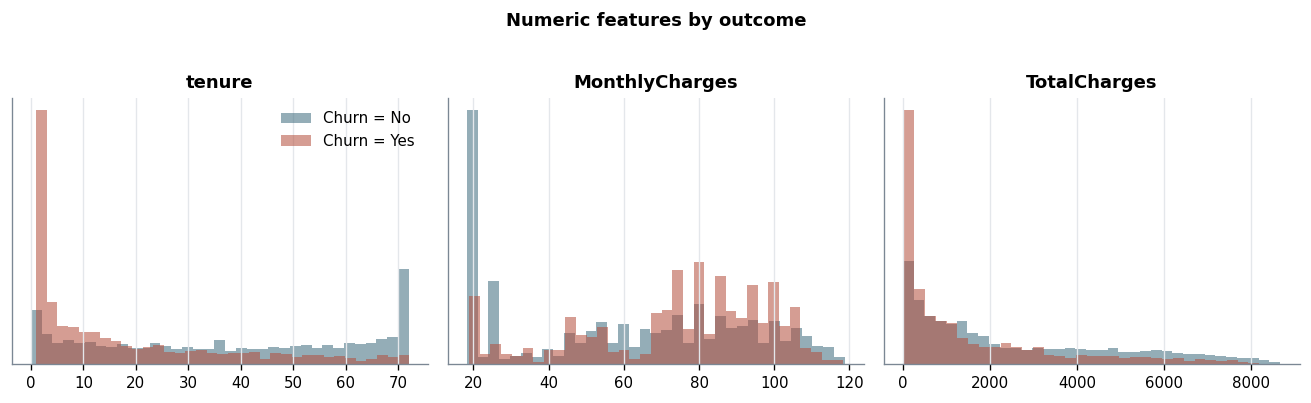

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))

for ax, column in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    for label, colour in [("No", COOL), ("Yes", ACCENT)]:
        values = df.loc[df["Churn"] == label, column]
        ax.hist(values, bins=35, density=True, alpha=0.55, color=colour, label=f"Churn = {label}")
    ax.set_title(column)
    ax.set_yticks([])
axes[0].legend(frameon=False)
fig.suptitle("Numeric features by outcome", y=1.03, fontweight="semibold")
plt.tight_layout()
plt.show()

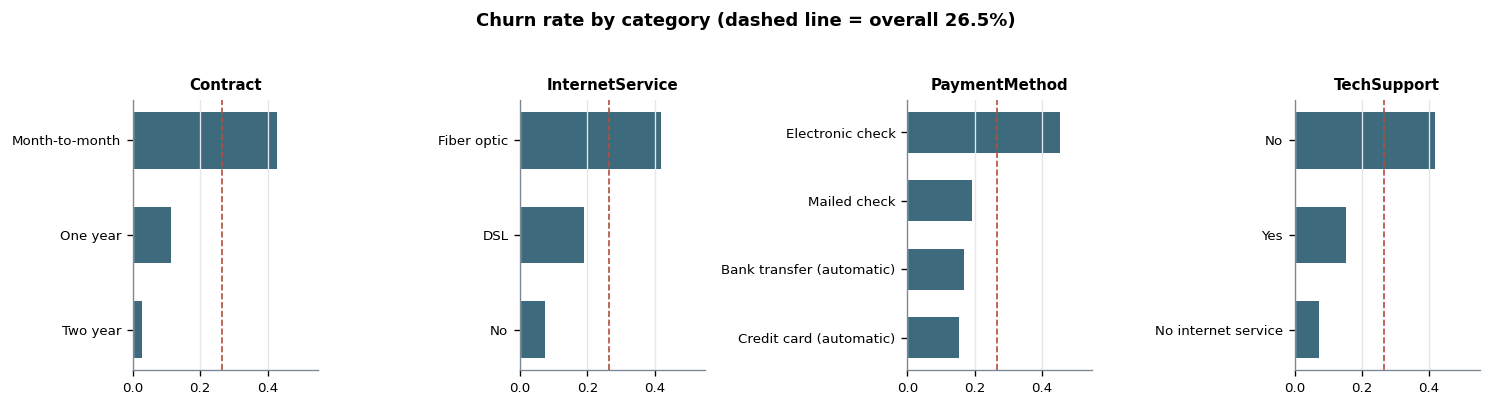

In [5]:
categorical = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.2))

for ax, column in zip(axes, categorical):
    rates = df.groupby(column)["Churn"].apply(lambda s: (s == "Yes").mean()).sort_values()
    ax.barh(rates.index, rates.values, color=COOL, height=0.6)
    ax.axvline(rate, color=ACCENT, linestyle="--", linewidth=1)
    ax.set_xlim(0, 0.55)
    ax.set_title(column, fontsize=9)
    ax.tick_params(labelsize=8)
    ax.grid(axis="y", visible=False)

fig.suptitle(f"Churn rate by category (dashed line = overall {rate:.1%})", y=1.04, fontweight="semibold")
plt.tight_layout()
plt.show()

## 4. Which features move together?

`TotalCharges` and `tenure` are highly correlated. A training-set cross-validation ablation compares raw and engineered features, but this correlation alone does not establish why the engineered features did or did not help.

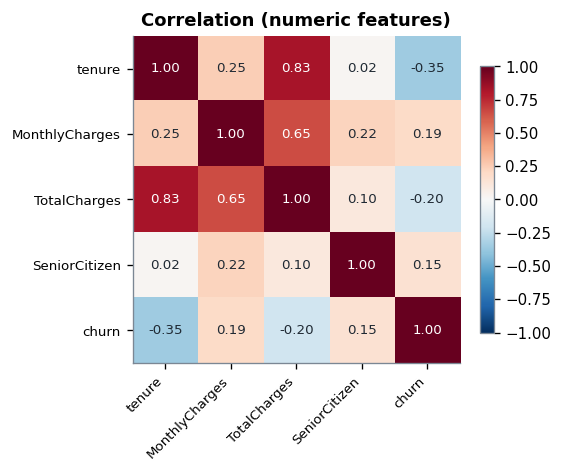

corr(tenure, TotalCharges) = 0.83


In [6]:
numeric = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]].copy()
numeric["churn"] = (df["Churn"] == "Yes").astype(int)
corr = numeric.corr()

fig, ax = plt.subplots(figsize=(4.4, 3.6))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else INK)
ax.set_title("Correlation (numeric features)")
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.8)
plt.show()

print(f"corr(tenure, TotalCharges) = {corr.loc['tenure', 'TotalCharges']:.2f}")

## Takeaways

| Finding | Consequence for the model |
|---|---|
| 26.5% churn rate | Compare average precision, precision and recall alongside accuracy |
| `TotalCharges` has 11 blanks, all `tenure == 0` | Treat these blanks as zero instead of dropping the records |
| `tenure`, `Contract`, `InternetService` show relationships with churn | Explore model importance, without treating association as causation |
| `tenure` and `TotalCharges` correlate at 0.83 | Check correlated inputs and test engineered features rather than assume an improvement |
| Month-to-month churn differs from the two-year rate | Preserve contract categories during encoding |

The notebook explores the full dataset, so these plots are descriptive. Model comparison and threshold selection use the training split; the random holdout is used for evaluation.